In [24]:
# CSP Analysis and Visualization
# Self-contained notebook with inline plotting functions

import sys
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Add project root to path
sys.path.append('..')

# Import required modules
from classification.model_training import get_model, load_model_data
from data.data_configs import SUBJECTS, CBRAMOD_CHANNELS
from data.data_loader import DataLoader

In [25]:
X_train, X_val, X_test, y_train, y_val, y_test, stim_train, stim_val, stim_test = load_model_data(
    model_name='csp',
    subjects=SUBJECTS,
    selected_channels=CBRAMOD_CHANNELS,
    split_strategy='normal'
)

✓ Loaded 33008 EEG samples from 13 subjects (per-subject scaled)
  Data shape: (33008, 19, 500), dtype: float32
  Memory usage: 1196.2 MB
Split data: 19804 train, 6602 val, 6602 test (total: 33008)


In [37]:
# Combine training and validation data for CSP training (as done in evaluation)
X_combined = np.vstack([X_train, X_val])
y_combined = np.concatenate([y_train, y_val])

print(f"Combined training data: {X_combined.shape[0]} samples")
print(f"Combined class distribution: {np.bincount(y_combined)}")

# Use 4 components for cleaner publication visualization
params = {
      "clf_type": "rf",
      "n_components": 4,  # Changed to 4 for cleaner paper visualization
      "reg": 0.05
}

# Create and train CSP model with optimal parameters
print(f"Training CSP model with {params['n_components']} components...")
csp_model = get_model('csp', params)

# Train the model (using smaller subset for speed)
print("Training CSP model...")
results = csp_model.train(X_combined, y_combined, X_test, y_test, verbose=True)

print(f"\nTraining Results:")
print(f"  Balanced Accuracy: {results['balanced_acc']:.4f}")
print(f"  Score: {results['score']:.4f}")
if 'auroc' in results and results['auroc'] is not None:
    print(f"  AUROC: {results['auroc']:.4f}")
    
print("✓ CSP model trained and ready for visualization!")

Combined training data: 26406 samples
Combined class distribution: [11774 14632]
Training CSP model with 4 components...
Training CSP model...
\n[CSP Training] Components: 4, Classifier: RF
Computing rank from data with rank=None
    Using tolerance 36 (2.2e-16 eps * 19 dim * 8.5e+15  max singular value)
    Estimated rank (data): 19
    data: rank 19 computed from 19 data channels with 0 projectors
Reducing data rank from 19 -> 19
Estimating class=False covariance using SHRINKAGE
Done.
Estimating class=True covariance using SHRINKAGE
Done.
\n============================================================
CSP - EVALUATION RESULTS
Balanced Accuracy: 0.5484
AUROC Score:      0.5633
\nConfusion Matrix:
                 Predicted
                 Non-Target  Target
Actual Non-Target    1162     1782
Actual Target        1090     2568
\nPredictions: {False: 2252, True: 4350}

Training Results:
  Balanced Accuracy: 0.5484
  Score: 0.5484
  AUROC: 0.5633
✓ CSP model trained and ready for visuali

In [32]:
# Create Publication-Ready CSP Plot (works with existing model)
import matplotlib.pyplot as plt
import numpy as np
import mne

def create_publication_csp_plot(csp_model, ch_names, figsize=(16, 4)):
    """Create a clean publication-ready CSP plot showing 4 key components in horizontal layout"""
    
    # Get CSP object
    if hasattr(csp_model, 'model') and hasattr(csp_model.model, 'model'):
        pipeline = csp_model.model.model
    elif hasattr(csp_model, 'model'):
        pipeline = csp_model.model
    else:
        pipeline = csp_model
    csp = pipeline.named_steps['csp']
    
    # Create MNE info
    ch_types = ['eeg'] * len(ch_names)
    info = mne.create_info(ch_names=ch_names, sfreq=500, ch_types=ch_types)
    montage = mne.channels.make_standard_montage('standard_1020')
    info.set_montage(montage, on_missing='ignore')
    
    # Get patterns
    n_components = csp.n_components
    all_patterns = csp.patterns_
    
    # Select components: first 2 and last 2 
    if n_components >= 4:
        selected_indices = [0, 1, n_components-2, n_components-1]
        titles = [
            'CSP-1: Non-Target (Max Variance)',
            'CSP-2: Non-Target', 
            f'CSP-{n_components-1}: Target',
            f'CSP-{n_components}: Target (Max Variance)'
        ]
    else:
        selected_indices = list(range(n_components))
        titles = [f'CSP-{i+1}' for i in range(n_components)]
    
    # Create figure with horizontal layout and tighter spacing
    fig, axes = plt.subplots(1, 4, figsize=figsize)
    
    # Plot each component
    for i, (comp_idx, title) in enumerate(zip(selected_indices, titles)):
        if i < len(selected_indices):
            pattern = all_patterns[comp_idx, :]
            
            im, _ = mne.viz.plot_topomap(
                pattern, info, axes=axes[i],
                show=False, contours=8, 
                cmap='RdBu_r', sensors=True,
                ch_type='eeg'
            )
            
            axes[i].set_title(title, fontsize=11, fontweight='bold', pad=20)
        else:
            axes[i].set_visible(False)
    
    # Adjust layout with tighter spacing between subplots
    plt.subplots_adjust(left=0.02, right=0.98, top=0.85, bottom=0.15, wspace=0.1)
    
    # Add legend at the bottom
    fig.text(0.5, 0.05, 
             'Blue: Higher activity for this condition | Red: Lower activity for this condition',
             ha='center', fontsize=10, style='italic')
    
    return fig

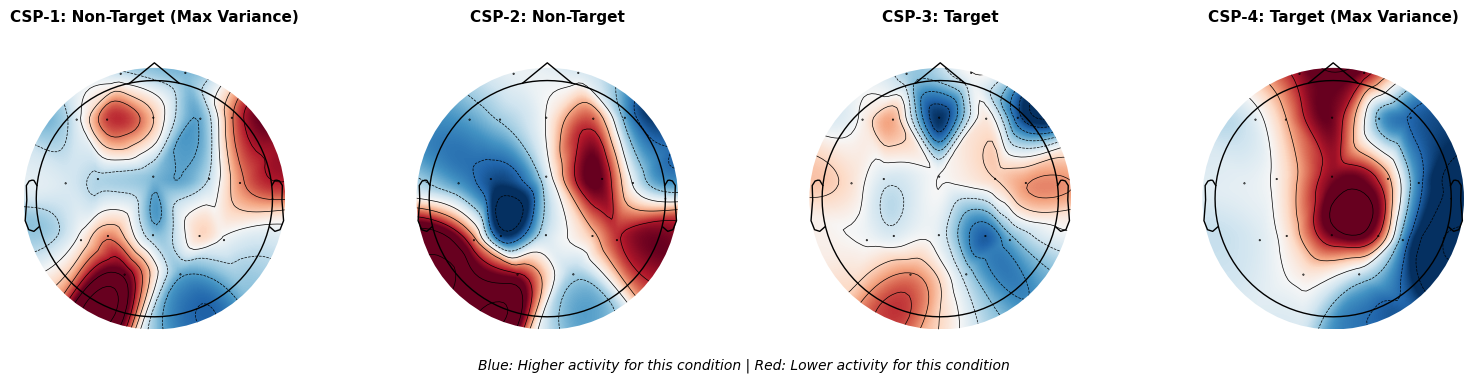

In [33]:

fig = create_publication_csp_plot(csp_model, CBRAMOD_CHANNELS, figsize=(16, 4))
plt.show()


In [34]:
# CSP Feature Distribution Analysis (inline function)
import seaborn as sns

def plot_csp_feature_distributions_inline(model, X_raw, y, n_plot=3):
    """
    Transforms the raw data using the trained CSP and plots histograms 
    of the resulting features showing class separability.
    """
    # Get CSP object from model
    if hasattr(model, 'model') and hasattr(model.model, 'model'):
        pipeline = model.model.model
    elif hasattr(model, 'model'):
        pipeline = model.model
    else:
        pipeline = model
    csp = pipeline.named_steps['csp']
    
    # Transform raw data to get the CSP features
    X_features = csp.transform(X_raw)
    
    n_components = X_features.shape[1]
    n_plot = min(n_plot, n_components // 2) # Plot pairs (first N and last N)
    
    fig, axes = plt.subplots(n_plot, 2, figsize=(12, 4 * n_plot))
    if n_plot == 1: 
        axes = axes.reshape(1, -1)
    
    # Indices of components to plot: First N and Last N
    # First N correspond to Class 0 variance, Last N to Class 1 variance
    indices_to_plot = list(range(n_plot)) + list(range(n_components - n_plot, n_components))
    
    colors = ['blue', 'red']
    labels = ['Non-Target', 'Target']
    
    for i, ax in enumerate(axes.flatten()):
        comp_idx = indices_to_plot[i]
        
        # Plot distribution for each class
        for class_idx in [0, 1]:
            # Extract features for this class
            feats = X_features[y == class_idx, comp_idx]
            
            sns.histplot(feats, color=colors[class_idx], label=labels[class_idx], 
                         kde=True, stat="density", alpha=0.4, ax=ax)
            
        ax.set_title(f"CSP Component #{comp_idx + 1}")
        ax.set_xlabel("Feature Value (Log-Variance)")
        ax.legend()
        ax.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

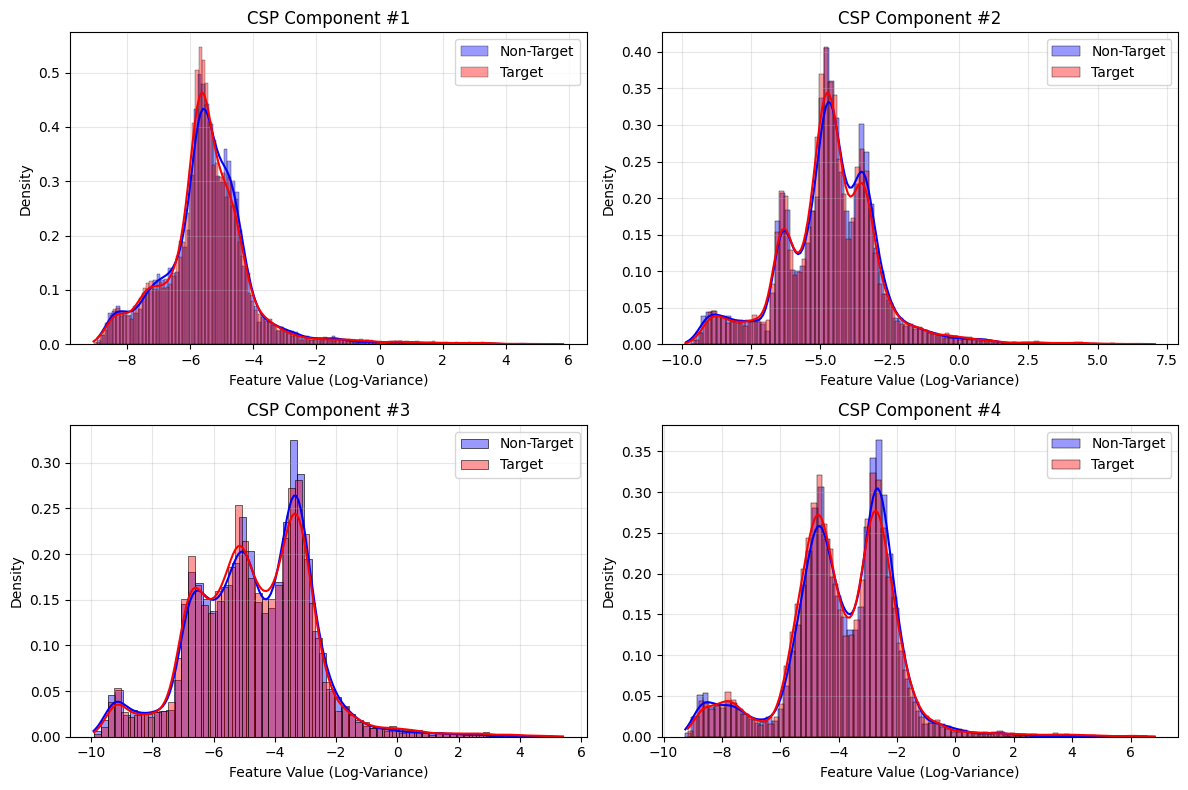

In [35]:
# Plot CSP Feature Distributions
plot_csp_feature_distributions_inline(
    model=csp_model,
    X_raw=X_combined,
    y=y_combined,
    n_plot=min(params['n_components'], 6)  # Plot up to 6 components
)